=== NOISE ROBUSTNESS EVALUATION (Trained on SNR_noiseless) ===
Noise_Level  Log_Loss  Accuracy  ROC_AUC
  noiseless  0.206535 95.749441 0.999192
       50dB  0.250130 94.407159 0.998036
       40dB  0.227704 95.078300 0.998761
       30dB  0.296259 95.973154 0.997515
       20dB  0.962193 73.228934 0.978586


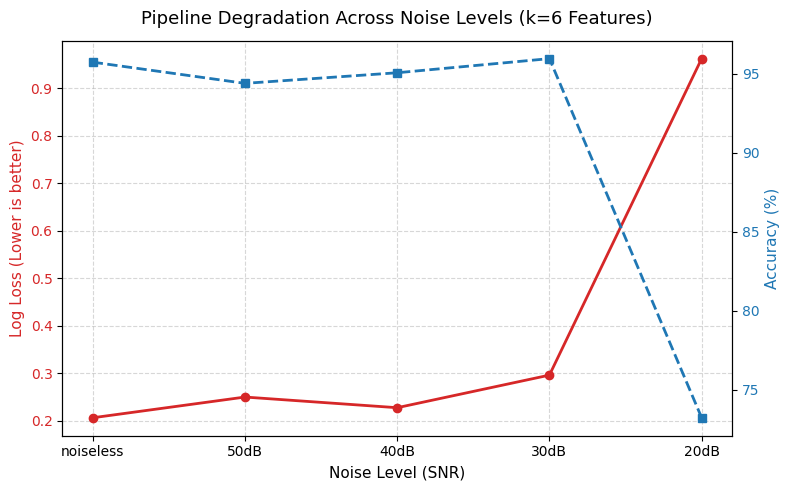

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from import_folder import PQD_INDICES, import_single_noiselevel_data

# -----------------------------------------------------------------------------
# 1. Train Pipeline on Clean Data (SNR_noiseless)
# -----------------------------------------------------------------------------
train_folder = "SNR_noiseless"
clean_data = import_single_noiselevel_data(train_folder)

X_clean = clean_data.drop(columns=["label"])
y_clean = clean_data["label"]

# Train-test split on clean data
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_clean, test_size=0.2, random_state=42, stratify=y_clean
)

pipeline_k6 = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("select_k", SelectKBest(score_func=f_classif, k=6)),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)

# Fit pipeline on training set
pipeline_k6.fit(X_train, y_train)

# -----------------------------------------------------------------------------
# 2. Evaluate Performance Across All Noise Levels
# -----------------------------------------------------------------------------
noise_folders = [
    "SNR_noiseless",
    "SNR_50dB",
    "SNR_40dB",
    "SNR_30dB",
    "SNR_20dB",
]
robustness_results = []

for folder in noise_folders:
    # Load test folder
    df_noise = import_single_noiselevel_data(folder)
    X_noise = df_noise.drop(columns=["label"])
    y_noise = df_noise["label"]

    # Predict probabilities and hard class labels
    y_probs = pipeline_k6.predict_proba(X_noise)
    y_preds = pipeline_k6.predict(X_noise)

    # Compute key evaluation metrics
    loss = log_loss(y_noise, y_probs)
    acc = accuracy_score(y_noise, y_preds)
    auc = roc_auc_score(
        y_noise, y_probs, multi_class="ovr", average="macro"
    )

    robustness_results.append(
        {
            "Noise_Level": folder.replace("SNR_", ""),
            "Log_Loss": loss,
            "Accuracy": acc * 100.0,
            "ROC_AUC": auc,
        }
    )

results_df = pd.DataFrame(robustness_results)

print("=== NOISE ROBUSTNESS EVALUATION (Trained on SNR_noiseless) ===")
print(results_df.to_string(index=False))

# -----------------------------------------------------------------------------
# 3. Plot Performance Degradation Curves
# -----------------------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(8, 5))

color = "tab:red"
ax1.set_xlabel("Noise Level (SNR)", fontsize=11)
ax1.set_ylabel("Log Loss (Lower is better)", color=color, fontsize=11)
ax1.plot(
    results_df["Noise_Level"],
    results_df["Log_Loss"],
    marker="o",
    color=color,
    linewidth=2,
    label="Log Loss",
)
ax1.tick_params(axis="y", labelcolor=color)
ax1.grid(True, linestyle="--", alpha=0.5)

ax2 = ax1.twinx()
color = "tab:blue"
ax2.set_ylabel("Accuracy (%)", color=color, fontsize=11)
ax2.plot(
    results_df["Noise_Level"],
    results_df["Accuracy"],
    marker="s",
    color=color,
    linewidth=2,
    linestyle="--",
    label="Accuracy",
)
ax2.tick_params(axis="y", labelcolor=color)

plt.title(
    "Pipeline Degradation Across Noise Levels (k=6 Features)",
    fontsize=13,
    pad=12,
)
fig.tight_layout()
plt.show()